# 01. Подготовка данных: загрузка, анализ (EDA), очистка

**Блок 2.1.** Датасет NASA C-MAPSS, поднабор FD001: 100 двигателей в обучающей части (наблюдения от запуска
до отказа) и 100 в тестовой (наблюдения обрываются до отказа, истинный остаточный ресурс дан отдельно).

Порядок работы:
1. Загрузка исходных файлов в слой `raw` PostgreSQL.
2. Проверка качества: пропуски, дубли, непрерывность циклов.
3. Анализ: срок жизни двигателей, целевая переменная, изменчивость датчиков, связь с износом, выбросы.
4. Очистка и запись в слой `cleaned`.

Целевая переменная (по постановке из блока 1): `target = 1`, если до отказа осталось 30 циклов или меньше.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data.cleaning import build_cleaned, find_low_variance_columns
from src.data.load_raw import SENSOR_COLS, SETTING_COLS, load_raw
from src.utils.db import get_engine

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40, "display.width", 160)
sns.set_theme(style="whitegrid")
HORIZON = 30          # горизонт прогноза в циклах (допущение: 7 дней ≈ 30 циклов)
MEASURE_COLS = SETTING_COLS + SENSOR_COLS
engine = get_engine()

## 1. Загрузка в слой raw

Функция `load_raw` создаёт схемы и перезагружает файлы; повторный запуск не создаёт дублей.

In [2]:
counts = load_raw(engine)
counts

{'test': 13096, 'train': 20631, 'rul_test': 100}

In [3]:
raw = pd.read_sql("SELECT * FROM raw.sensor_readings ORDER BY dataset, unit_id, cycle", engine)
rul_test = pd.read_sql("SELECT unit_id, rul FROM raw.rul_test ORDER BY unit_id", engine)
train = raw[raw["dataset"] == "train"].reset_index(drop=True)
test = raw[raw["dataset"] == "test"].reset_index(drop=True)
print("train:", train.shape, " test:", test.shape, " rul_test:", rul_test.shape)
train.head()

train: (20631, 30)  test: (13096, 30)  rul_test: (100, 2)


,id,dataset,unit_id,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,s_11,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,source,loaded_at
0,101182,train,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.4190,train_FD001.txt,2026-11-20 06:31:11.950190+00:00
1,101183,train,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.00,23.4236,train_FD001.txt,2026-11-20 06:31:11.950190+00:00
2,101184,train,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442,train_FD001.txt,2026-11-20 06:31:11.950190+00:00
3,101185,train,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739,train_FD001.txt,2026-11-20 06:31:11.950190+00:00
4,101186,train,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393.0,2388.0,100.0,38.90,23.4044,train_FD001.txt,2026-11-20 06:31:11.950190+00:00


## 2. Качество данных

In [4]:
def quality(df):
    g = df.groupby("unit_id")["cycle"]
    return pd.Series({
        "строк": len(df),
        "двигателей": df["unit_id"].nunique(),
        "пропусков (ячеек)": int(df[["unit_id", "cycle"] + MEASURE_COLS].isna().sum().sum()),
        "дублей по (двигатель, цикл)": int(df.duplicated(["unit_id", "cycle"]).sum()),
        "двигателей с разрывом в циклах": int((g.max() - g.min() + 1 != g.count()).sum()),
        "все начинаются с цикла 1": bool((g.min() == 1).all()),
    })

pd.DataFrame({"train": quality(train), "test": quality(test)})

,train,test
строк,20631,13096
двигателей,100,100
пропусков (ячеек),0,0
"дублей по (двигатель, цикл)",0,0
двигателей с разрывом в циклах,0,0
все начинаются с цикла 1,True,True


In [5]:
print("Истинный RUL тестовых двигателей:")
print(rul_test["rul"].describe().round(1).to_string())
print("Отрицательных значений:", int((rul_test["rul"] < 0).sum()),
      "| двигатели совпадают с test:", set(rul_test["unit_id"]) == set(test["unit_id"]))

Истинный RUL тестовых двигателей:
count    100.0
mean      75.5
std       41.8
min        7.0
25%       32.8
50%       86.0
75%      112.2
max      145.0
Отрицательных значений: 0 | двигатели совпадают с test: True


## 3. Срок жизни двигателей и целевая переменная

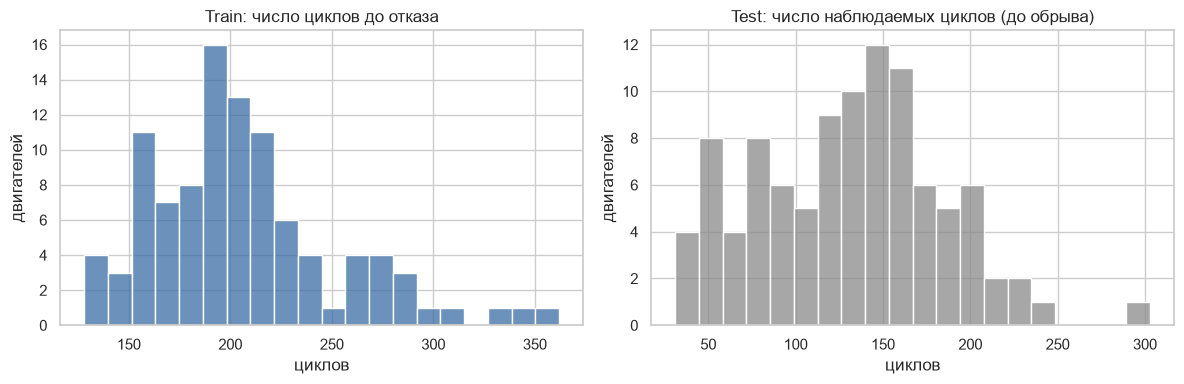

Срок жизни (train): {'count': 100.0, 'mean': 206.3, 'std': 46.3, 'min': 128.0, '25%': 177.0, '50%': 199.0, '75%': 229.2, 'max': 362.0}


In [6]:
life = train.groupby("unit_id")["cycle"].max()
observed = test.groupby("unit_id")["cycle"].max()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(life, bins=20, ax=ax[0], color="#3b6ea5")
ax[0].set(title="Train: число циклов до отказа", xlabel="циклов", ylabel="двигателей")
sns.histplot(observed, bins=20, ax=ax[1], color="#8a8a8a")
ax[1].set(title="Test: число наблюдаемых циклов (до обрыва)", xlabel="циклов", ylabel="двигателей")
plt.tight_layout(); fig.savefig(FIG_DIR / "01_lifetimes.png", dpi=120); plt.show()
print("Срок жизни (train):", life.describe().round(1).to_dict())

In [7]:
train["rul"] = train.groupby("unit_id")["cycle"].transform("max") - train["cycle"]
train["target"] = (train["rul"] <= HORIZON).astype(int)
share = train["target"].value_counts().sort_index()
print(f"Класс 0: {share[0]} строк, класс 1: {share[1]} строк, доля класса 1 = {train['target'].mean():.2%}")

Класс 0: 17531 строк, класс 1: 3100 строк, доля класса 1 = 15.03%


## 4. Изменчивость показаний

Если показание почти не меняется, оно не может подсказать, что двигатель изнашивается.

In [8]:
profile = pd.DataFrame({
    "уникальных": train[MEASURE_COLS].nunique(),
    "std": train[MEASURE_COLS].std(),
    "min": train[MEASURE_COLS].min(),
    "max": train[MEASURE_COLS].max(),
})
low_var = find_low_variance_columns(train)
profile["удалить"] = profile.index.isin(low_var)
print("Не больше 2 уникальных значений на train:", low_var)
profile

Не больше 2 уникальных значений на train: ['setting_3', 's_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']


,уникальных,std,min,max,удалить
setting_1,158,2.187313e-03,-0.0087,0.0087,False
setting_2,13,2.930621e-04,-0.0006,0.0006,False
setting_3,1,0.000000e+00,100.0000,100.0000,True
s_1,1,0.000000e+00,518.6700,518.6700,True
s_2,310,5.000533e-01,641.2100,644.5300,False
s_3,3012,6.131150e+00,1571.0400,1616.9100,False
s_4,4051,9.000605e+00,1382.2500,1441.4900,False
s_5,1,5.329200e-15,14.6200,14.6200,True
s_6,2,1.388985e-03,21.6000,21.6100,True
s_7,513,8.850923e-01,549.8500,556.0600,False


## 5. Связь показаний с износом

Корреляция Спирмена с остаточным ресурсом (RUL): чем ближе к ±1, тем сильнее показание меняется по мере износа.

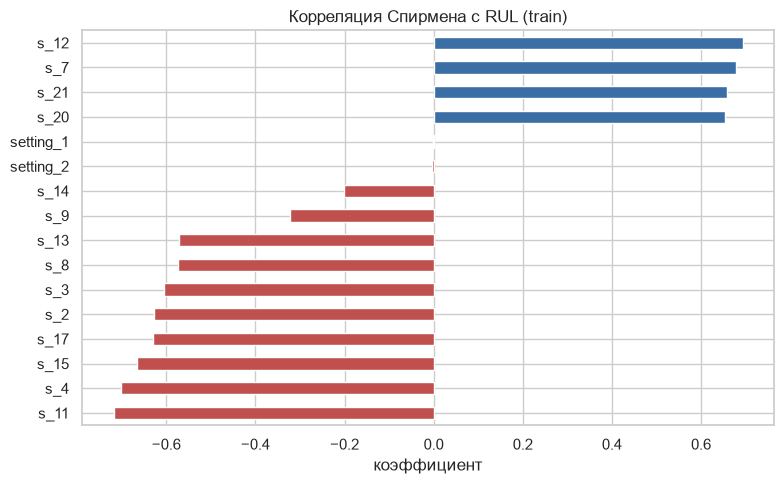

,spearman
s_11,-0.718
s_4,-0.702
s_15,-0.666
s_17,-0.629
s_2,-0.629
s_3,-0.606
s_8,-0.574
s_13,-0.573
s_9,-0.322
s_14,-0.202


In [9]:
informative = [c for c in MEASURE_COLS if c not in low_var]
corr = train[informative + ["rul"]].corr(method="spearman")["rul"].drop("rul").sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
corr.plot.barh(ax=ax, color=np.where(corr < 0, "#c0504d", "#3b6ea5"))
ax.set(title="Корреляция Спирмена с RUL (train)", xlabel="коэффициент")
plt.tight_layout(); fig.savefig(FIG_DIR / "01_corr_rul.png", dpi=120); plt.show()
corr.round(3).to_frame("spearman")

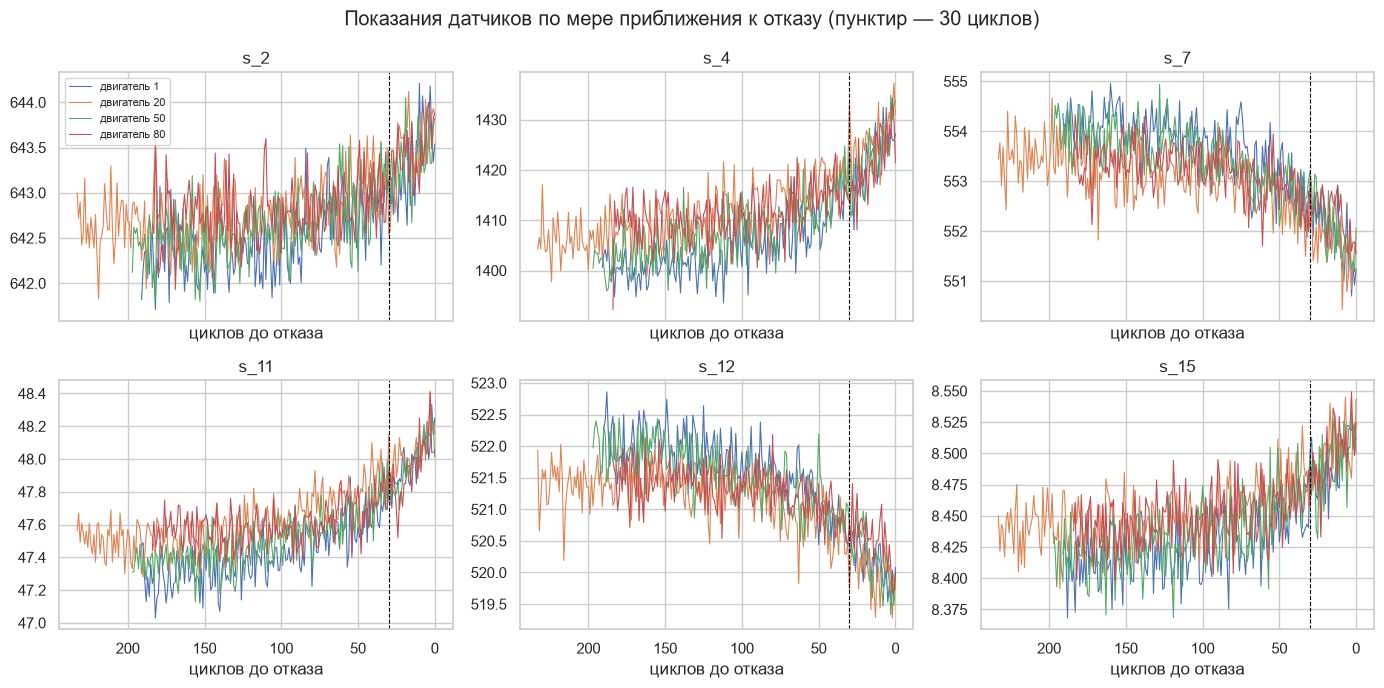

In [10]:
show = ["s_2", "s_4", "s_7", "s_11", "s_12", "s_15"]
units = [1, 20, 50, 80]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, col in zip(axes.ravel(), show):
    for u in units:
        d = train[train["unit_id"] == u]
        ax.plot(d["rul"], d[col], lw=0.8, label=f"двигатель {u}")
    ax.axvline(HORIZON, color="black", ls="--", lw=0.8)
    ax.set(title=col, xlabel="циклов до отказа")
axes[0, 0].invert_xaxis()   # оси общие: переворачиваем один раз, время идёт слева направо к отказу
axes[0, 0].legend(fontsize=8)
fig.suptitle("Показания датчиков по мере приближения к отказу (пунктир — 30 циклов)")
plt.tight_layout(); fig.savefig(FIG_DIR / "01_sensor_trends.png", dpi=120); plt.show()

## 6. Выбросы

Выброс по правилу межквартильного размаха (IQR): значение за пределами [Q1 − 1,5·IQR; Q3 + 1,5·IQR]. Важно понять, это ошибки измерения или сигнал износа.

In [11]:
q1, q3 = train[informative].quantile(0.25), train[informative].quantile(0.75)
iqr = q3 - q1
out_mask = (train[informative] < q1 - 1.5 * iqr) | (train[informative] > q3 + 1.5 * iqr)
row_out = out_mask.any(axis=1)
print("Выбросов по столбцам:", out_mask.sum()[lambda s: s > 0].to_dict())
print(f"Строк хотя бы с одним выбросом: {row_out.sum()} из {len(train)}")
print(f"Из них в последних {HORIZON} циклах перед отказом: {(row_out & (train['target'] == 1)).sum()} "
      f"({(row_out & (train['target'] == 1)).sum() / row_out.sum():.0%}), "
      f"хотя эти циклы составляют лишь {train['target'].mean():.0%} всех строк")

Выбросов по столбцам: {'setting_1': 105, 's_2': 128, 's_3': 165, 's_4': 120, 's_7': 110, 's_8': 320, 's_9': 1686, 's_11': 167, 's_12': 146, 's_13': 161, 's_14': 1543, 's_15': 120, 's_17': 81, 's_20': 117, 's_21': 136}
Строк хотя бы с одним выбросом: 2521 из 20631
Из них в последних 30 циклах перед отказом: 1849 (73%), хотя эти циклы составляют лишь 15% всех строк


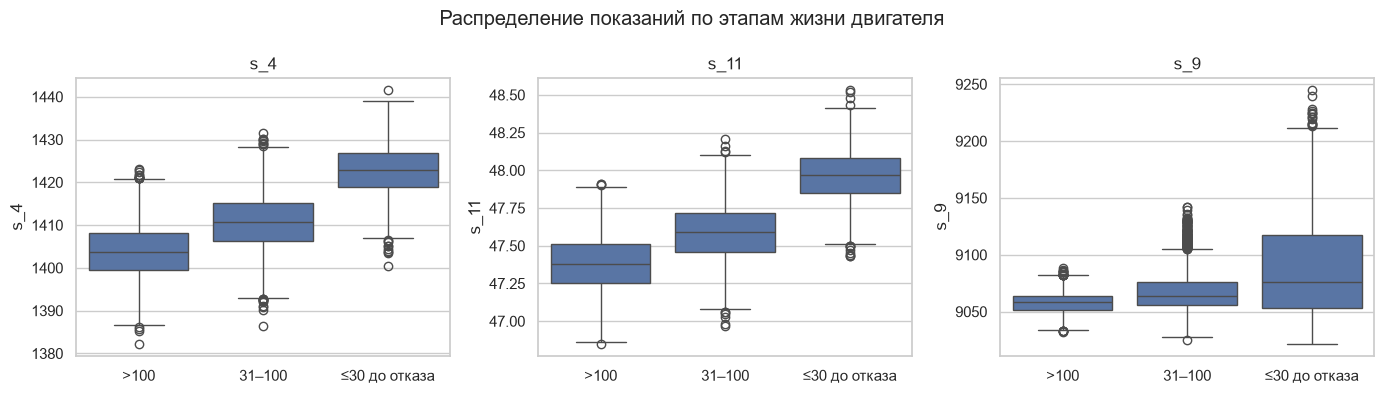

In [12]:
train["этап"] = pd.cut(train["rul"], [-1, 30, 100, 1000], labels=["≤30 до отказа", "31–100", ">100"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["s_4", "s_11", "s_9"]):
    sns.boxplot(data=train, x="этап", y=col, ax=ax, order=[">100", "31–100", "≤30 до отказа"])
    ax.set(title=col, xlabel="")
fig.suptitle("Распределение показаний по этапам жизни двигателя")
plt.tight_layout(); fig.savefig(FIG_DIR / "01_outliers_by_stage.png", dpi=120); plt.show()

## 7. Взаимосвязь датчиков и сравнение train / test

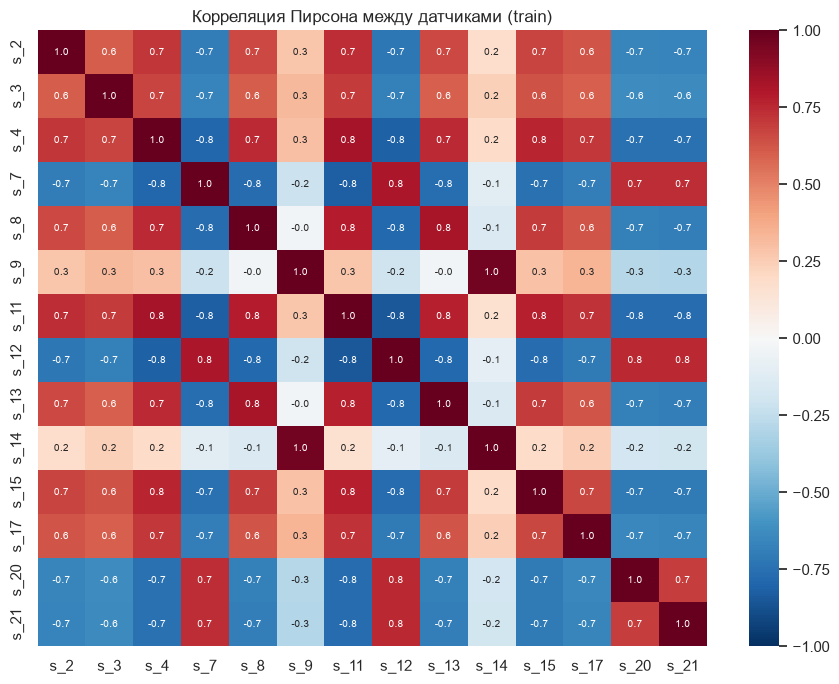

Пары с |r| > 0,9: [('s_9', 's_14', np.float64(0.963))]


In [13]:
sens = [c for c in informative if c.startswith("s_")]
c = train[sens].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(c, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 7})
ax.set_title("Корреляция Пирсона между датчиками (train)")
plt.tight_layout(); fig.savefig(FIG_DIR / "01_sensor_corr.png", dpi=120); plt.show()
pairs = [(a, b, round(c.loc[a, b], 3)) for i, a in enumerate(sens) for b in sens[i + 1:] if abs(c.loc[a, b]) > 0.9]
print("Пары с |r| > 0,9:", pairs)

In [14]:
outside = {col: int(((test[col] < train[col].min()) | (test[col] > train[col].max())).sum()) for col in informative}
outside = {k: v for k, v in outside.items() if v}
print(f"Значений test вне диапазона train: {sum(outside.values())} из {len(test) * len(informative)} ->", outside)

Значений test вне диапазона train: 18 из 209536 -> {'setting_2': 5, 's_2': 2, 's_3': 3, 's_8': 1, 's_11': 2, 's_12': 3, 's_21': 2}


## 8. Очистка и запись в слой cleaned

Правила (реализованы в `src/data/cleaning.py`):
1. Удаляются строки без номера двигателя или цикла, с циклом < 1 или с нечисловыми показаниями.
2. Удаляются дубли по ключу (набор, двигатель, цикл), остаётся последняя загруженная запись.
3. Удаляются столбцы, у которых на train не больше 2 разных значений. Список определяется только по train,
   чтобы тестовые данные не влияли на обработку.
4. Выбросы **не удаляются** (раздел 6).

Для файлов FD001 правила 1–2 ничего не удаляют, но они нужны для данных из потока (Kafka), где возможны
повторы и испорченные сообщения.

In [15]:
report = build_cleaned(engine)
report

{'rows_in': 33727,
 'dropped_bad_key': 0,
 'dropped_bad_values': 0,
 'dropped_duplicates': 0,
 'rows_out': 33727,
 'dropped_columns': ['setting_3',
  's_1',
  's_5',
  's_6',
  's_10',
  's_16',
  's_18',
  's_19'],
 'rul_rows': 100}

In [16]:
cleaned = pd.read_sql("SELECT * FROM cleaned.sensor_readings", engine)
print("cleaned.sensor_readings:", cleaned.shape)
print("Столбцы:", list(cleaned.columns))

cleaned.sensor_readings: (33727, 19)
Столбцы: ['dataset', 'unit_id', 'cycle', 'setting_1', 'setting_2', 's_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']


## 9. Выводы

- **Качество исходных данных высокое:** пропусков, дублей и разрывов в циклах нет, каждый двигатель
  начинается с цикла 1; истинный RUL есть для всех 100 тестовых двигателей.
- **Срок жизни** двигателей в train — от 128 до 362 циклов (медиана 199). В test наблюдения обрываются
  на 31–303 цикле.
- **Дисбаланс классов:** при горизонте 30 циклов положительный класс — 15,03% строк (3 100 из 20 631).
  Поэтому для сравнения моделей нужна PR-AUC, а порог подбирается под Recall.
- **8 столбцов неинформативны** (не больше 2 значений): `setting_3`, `s_1`, `s_5`, `s_6`, `s_10`, `s_16`,
  `s_18`, `s_19`. Они удалены при очистке.
- **Сильнее всего с износом связаны** `s_11`, `s_4`, `s_12`, `s_7`, `s_15` (|ρ| ≈ 0,67–0,72).
  `setting_1` и `setting_2` с износом не связаны (|ρ| < 0,01) — решение об их исключении принимается
  на этапе отбора признаков.
- **Выбросы — сигнал износа, а не ошибки:** из 2 521 строки с выбросами (по информативным столбцам)
  1 849, то есть 73%, приходятся на последние 30 циклов, хотя эти циклы составляют 15% данных.
  Выбросы сохранены.
- `s_9` и `s_14` почти дублируют друг друга (r = 0,963) — учесть при отборе признаков.
- Значения test почти всегда в диапазоне train (18 выходов из 13 096 × 16) — данные однородны; контроль
  выхода за диапазон пригодится для мониторинга дрейфа в потоке.